# 基于深度学习的脑部肿瘤检测算法建模

## 1. 任务描述
当大脑中形成异常细胞时，就会发生脑肿瘤。肿瘤主要有两种类型：癌性（恶性）肿瘤和良性肿瘤。恶性肿瘤可分为原发性肿瘤和继发性肿瘤，前者始于大脑，后者从其他地方扩散，称为脑转移瘤。所有类型的脑肿瘤都可能产生不同的症状，这取决于所涉及的大脑部分。这些症状可能包括头痛、癫痫发作、视力问题、呕吐和精神变化。头痛通常在早上更严重，并伴随呕吐而消失。其他症状可能包括走路、说话或感觉困难。随着疾病的发展，可能会出现无意识状态。

本项目利用 TensorFlow、Keras 等深度学习工具包构建 VGG16、RestNet、InceptionV3 等神经网络，实现对脑部肿瘤 MRI 扫描影像的识别。

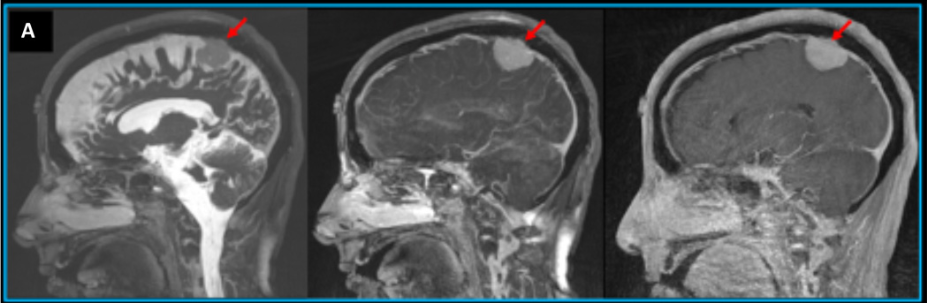

## 2. 依赖包导入

In [48]:
# !pip install imutils keras opencv-python plotly -i https://pypi.tuna.tsinghua.edu.cn/simple

In [2]:
from IPython.display import clear_output
import tensorflow as tf
from tensorflow.keras.applications.vgg19 import VGG19,preprocess_input
from tensorflow.keras.applications.xception import Xception,preprocess_input
from tensorflow.keras.applications.inception_v3 import InceptionV3
from tensorflow.keras.applications.resnet50 import ResNet50

In [3]:
import numpy as np 
from tqdm import tqdm
import cv2
import os
import shutil
import itertools
import imutils
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelBinarizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import plotly.graph_objs as go
from plotly.offline import init_notebook_mode, iplot
from plotly import tools

from keras.preprocessing.image import ImageDataGenerator
from keras.applications.vgg16 import VGG16, preprocess_input
from keras import layers
from keras.models import Model, Sequential
from keras.optimizers import Adam, RMSprop
from keras.callbacks import EarlyStopping
from tensorflow.keras import regularizers

init_notebook_mode(connected=True)
RANDOM_SEED = 123

In [4]:
from matplotlib.font_manager import fontManager
import os
 
fonts = [font.name for font in fontManager.ttflist 
             if os.path.exists(font.fname) and os.stat(font.fname).st_size>1e6]
print(list(fonts))

# 显示中文,解决图中无法显示中文的问题
plt.rcParams['font.sans-serif']=['KaiTi']
 
# 设置显示中文后,负号显示受影响。解决坐标轴上乱码问题
plt.rcParams['axes.unicode_minus']=False

['Yu Gothic', 'STLiti', 'MingLiU-ExtB', 'SimHei', 'Microsoft YaHei', 'STSong', 'Segoe UI Historic', 'STHupo', 'Malgun Gothic', 'STXingkai', 'STXinwei', 'KaiTi', 'Segoe UI Emoji', 'Calibri', 'STXihei', 'Nirmala UI', 'Malgun Gothic', 'Yu Gothic', 'FZYaoTi', 'STCaiyun', 'DengXian', 'Gabriola', 'Yu Gothic', 'DengXian', 'Microsoft YaHei', 'Microsoft JhengHei', 'Arial', 'DengXian', 'Calibri', 'FZShuTi', 'STZhongsong', 'Calibri', 'SimSun-ExtB', 'Calibri', 'Nirmala UI', 'Segoe UI Variable', 'STKaiti', 'Microsoft JhengHei', 'SimSun', 'Times New Roman', 'Microsoft YaHei', 'STFangsong', 'Calibri', 'Times New Roman', 'Microsoft JhengHei', 'Segoe UI Symbol', 'Cambria', 'MS Gothic', 'Calibri', 'FangSong', 'Nirmala UI', 'Malgun Gothic', 'LiSu', 'Yu Gothic', 'YouYuan']


## 3. 数据读取与数据集扩充
利用图像的旋转、放大、剪切、对调等方式，实现对图像数据集的扩充。

In [19]:
#Setting some inital parameters
height, width = 224, 224
batch_size=64

In [24]:
data_dir = 'dataset'
class_map = {'无肿瘤': 0, '胶质瘤': 1, '垂体瘤': 2, '脑膜瘤': 3}
class_name_dict = {0: '无肿瘤', 1: '胶质瘤', 2: '垂体瘤', 3: '脑膜瘤'}

def image_generator(height,width):
    datagen = ImageDataGenerator(
            rescale=1./255.,
            validation_split=0.2,
            rotation_range=10,
            width_shift_range=0.05,
            height_shift_range=0.05,
            # shear_range=0.05,
            brightness_range=[0.5, 1.5],
            )
    train_ds = datagen.flow_from_directory(
            data_dir,
            batch_size=batch_size,
            subset="training",
            #color_mode = 'grayscale',
            shuffle=True,
            class_mode='categorical',
            target_size=(height, width),
            classes=class_map
            )
    val_ds = datagen.flow_from_directory(
              data_dir,
              subset="validation",
              #seed=123,
              #color_mode = 'grayscale',
              class_mode='categorical',
              target_size=(height, width),
              batch_size=batch_size,
            classes=class_map
            )
    return train_ds, val_ds

train_ds, val_ds = image_generator(height,width)

total_image = np.concatenate([train_ds.labels,val_ds.labels])

class_count = {}
for c in class_map:
    count = len(np.where(total_image==0)[0])
    class_count[c] = count
    
print('\n\n', class_count)

Found 5619 images belonging to 4 classes.
Found 1404 images belonging to 4 classes.


 {'无肿瘤': 2000, '胶质瘤': 2000, '垂体瘤': 2000, '脑膜瘤': 2000}


### 样例数据可视化

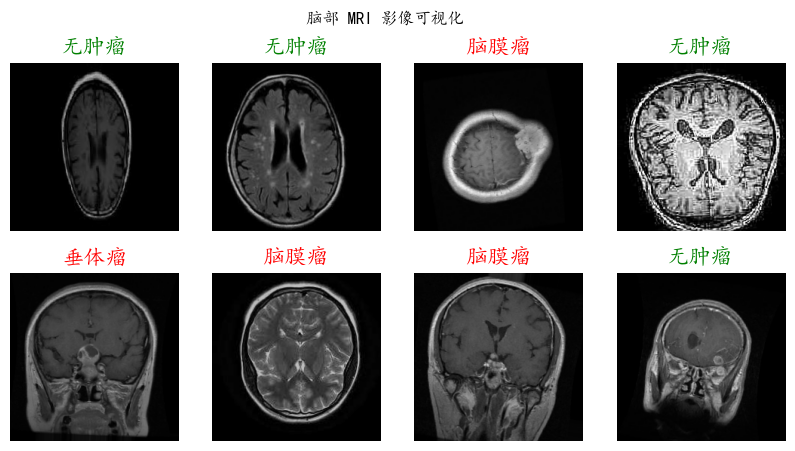

In [23]:
fig, ax = plt.subplots(2, 4, figsize=(10, 5))
fig.suptitle("脑部 MRI 影像可视化")
for k in range(8):
    images, labels = train_ds.next()
    i, j = k//4, k%4
    ax[i, j].imshow(images[0])

    index = np.argmax(labels[i])  # get image index
    class_name = class_name_dict[int(index)]
    if class_name == '无肿瘤':
        ax[i, j].set_title(class_name, color= 'green', fontsize= 16)
    else:
        ax[i, j].set_title(class_name, color= 'red', fontsize= 16)
        
    ax[i, j].axis('off')
plt.show()

## 4. 深度卷积神经网络模型构建

## 4.1 VGG16 Base Model 
VGG（Visual Geometry Group）是一个视觉几何组在2014年提出的深度卷积神经网络架构。VGG在2014年ImageNet图像分类竞赛亚军，定位竞赛冠军；VGG网络采用连续的小卷积核（3x3）和池化层构建深度神经网络，网络深度可以达到16层或19层，其中VGG16和VGG19最为著名。

VGG16和VGG19网络架构非常相似，都由多个卷积层和池化层交替堆叠而成，最后使用全连接层进行分类。两者的区别在于网络的深度和参数量，VGG19相对于VGG16增加了3个卷积层和一个全连接层，参数量也更多。

VGG网络被广泛应用于图像分类、目标检测、语义分割等计算机视觉任务中，并且其网络结构的简单性和易实现性使得VGG成为了深度学习领域的经典模型之一。
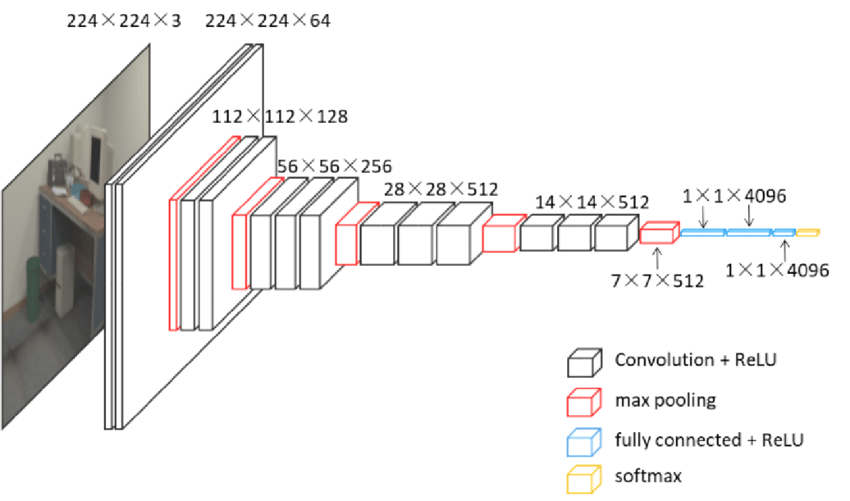

### 模型构建

In [25]:
input_shape = (height, width, 3)
base_model = tf.keras.applications.vgg16.VGG16(
    weights='./pretrained_models/vgg16_weights_tf_dim_ordering_tf_kernels_notop.h5', 
    include_top=False,
    input_shape=input_shape
)
base_model.trainable = False

model_vgg16 = tf.keras.Sequential()
model_vgg16.add(base_model)
model_vgg16.add(tf.keras.layers.Flatten())

model_vgg16.add(tf.keras.layers.Dense(4, activation='softmax'))

model_vgg16.compile(loss='categorical_crossentropy', 
              optimizer=tf.keras.optimizers.Adam(0.001),
              metrics=['acc'])
model_vgg16.summary()

Model: "sequential_3"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 vgg16 (Functional)          (None, 7, 7, 512)         14714688  
                                                                 
 flatten_3 (Flatten)         (None, 25088)             0         
                                                                 
 dense_3 (Dense)             (None, 4)                 100356    
                                                                 
Total params: 14815044 (56.51 MB)
Trainable params: 100356 (392.02 KB)
Non-trainable params: 14714688 (56.13 MB)
_________________________________________________________________


### 模型训练

In [26]:
checkpoint = tf.keras.callbacks.ModelCheckpoint('save_models/vgg16_best.h5', monitor='acc', verbose=1, mode='max',save_best_only=True)
early = tf.keras.callbacks.EarlyStopping(monitor="acc", mode="max",restore_best_weights=True, patience=5)
callbacks_list = [checkpoint,early]

history = model_vgg16.fit(
        train_ds,
        validation_data=val_ds,
        epochs=25, 
        shuffle=True, 
        verbose=True,
        callbacks=callbacks_list)

Epoch 1/25
88/88 [==============================] - ETA: 0s - loss: 0.6459 - acc: 0.7654
Epoch 1: acc improved from -inf to 0.76544, saving model to save_models\vgg16_best.h5
88/88 [==============================] - 789s 9s/step - loss: 0.6459 - acc: 0.7654 - val_loss: 0.4368 - val_acc: 0.8355


D:\Python3.10.6\lib\site-packages\keras\src\engine\training.py:3103: UserWarning:

You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.



Epoch 2/25
88/88 [==============================] - ETA: 0s - loss: 0.2958 - acc: 0.8930
Epoch 2: acc improved from 0.76544 to 0.89304, saving model to save_models\vgg16_best.h5
88/88 [==============================] - 774s 9s/step - loss: 0.2958 - acc: 0.8930 - val_loss: 0.3733 - val_acc: 0.8397
Epoch 3/25
88/88 [==============================] - ETA: 0s - loss: 0.2356 - acc: 0.9158
Epoch 3: acc improved from 0.89304 to 0.91582, saving model to save_models\vgg16_best.h5
88/88 [==============================] - 775s 9s/step - loss: 0.2356 - acc: 0.9158 - val_loss: 0.2956 - val_acc: 0.8896
Epoch 4/25
88/88 [==============================] - ETA: 0s - loss: 0.2184 - acc: 0.9228
Epoch 4: acc improved from 0.91582 to 0.92276, saving model to save_models\vgg16_best.h5
88/88 [==============================] - 811s 9s/step - loss: 0.2184 - acc: 0.9228 - val_loss: 0.2848 - val_acc: 0.8697
Epoch 5/25
88/88 [==============================] - ETA: 0s - loss: 0.1601 - acc: 0.9438
Epoch 5: acc impr

#### 绘制模型训练的损失函数

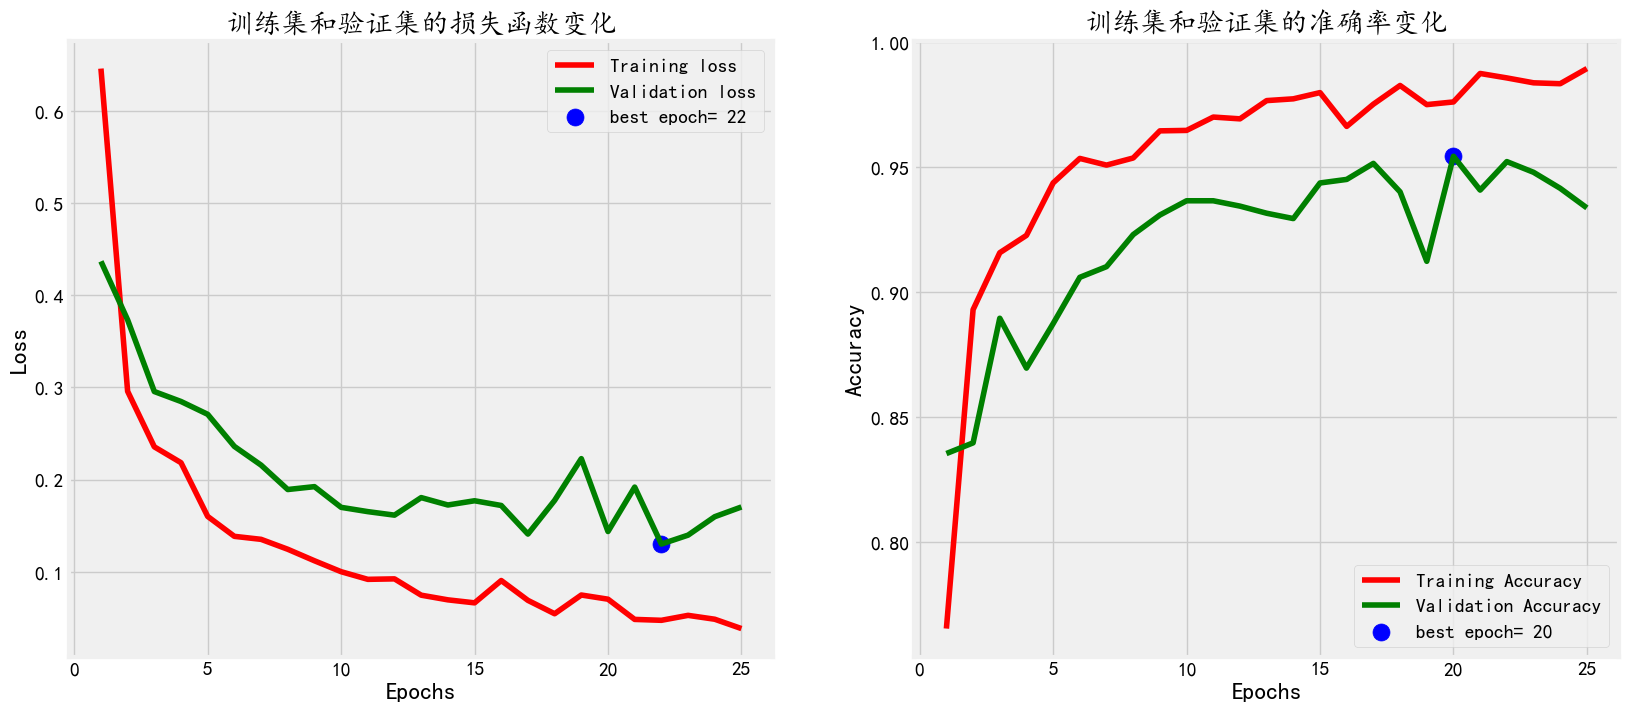

In [27]:
# Define needed variables
tr_acc = history.history['acc']
tr_loss = history.history['loss']
val_acc = history.history['val_acc']
val_loss = history.history['val_loss']
index_loss = np.argmin(val_loss)
val_lowest = val_loss[index_loss]
index_acc = np.argmax(val_acc)
acc_highest = val_acc[index_acc]
Epochs = [i+1 for i in range(len(tr_acc))]
loss_label = f'best epoch= {str(index_loss + 1)}'
acc_label = f'best epoch= {str(index_acc + 1)}'

# Plot training history
plt.figure(figsize= (20, 8))
plt.style.use('fivethirtyeight')

plt.subplot(1, 2, 1)
plt.plot(Epochs, tr_loss, 'r', label= 'Training loss')
plt.plot(Epochs, val_loss, 'g', label= 'Validation loss')
plt.scatter(index_loss + 1, val_lowest, s= 150, c= 'blue', label= loss_label)
plt.title('训练集和验证集的损失函数变化')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(Epochs, tr_acc, 'r', label= 'Training Accuracy')
plt.plot(Epochs, val_acc, 'g', label= 'Validation Accuracy')
plt.scatter(index_acc + 1 , acc_highest, s= 150, c= 'blue', label= acc_label)
plt.title('训练集和验证集的准确率变化')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout
plt.show()

### 模型评估

In [28]:
train_result = model_vgg16.evaluate(train_ds)
val_result = model_vgg16.evaluate(val_ds)

vgg16_eval_result = pd.DataFrame(zip(train_result,val_result),columns=['Train','Val'],index=['Loss','Acc'])
vgg16_eval_result

22/22 [==============================] - 240s 11s/step - loss: 0.1612 - acc: 0.9395


,Train,Val
Loss,0.061926,0.161204
Acc,0.975440,0.939459


In [37]:
ypred_val = model_vgg16.predict(val_ds[0][0])
ypred_val = np.argmax(ypred_val, axis=1)

true_val = np.argmax(val_ds[0][-1], axis=1)

print("混淆矩阵：")
print(confusion_matrix(true_val, ypred_val))
print("详细评估指标：")
print('\n',classification_report(ypred_val, true_val))

2/2 [==============================] - 11s 5s/step
混淆矩阵：
[[16  0  0  0]
 [ 0  7  0  0]
 [ 0  0 19  1]
 [ 1  5  1 14]]
详细评估指标：

               precision    recall  f1-score   support

           0       1.00      0.94      0.97        17
           1       1.00      0.58      0.74        12
           2       0.95      0.95      0.95        20
           3       0.67      0.93      0.78        15

    accuracy                           0.88        64
   macro avg       0.90      0.85      0.86        64
weighted avg       0.91      0.88      0.87        64



## 4.2 InceptionV3 Base Model
深度神经网络(Deep Neural Networks, DNN)或深度卷积网络中的Inception模块是由Google的Christian Szegedy等人提出，包括Inception-v1、Inception-v2、Inception-v3、Inception-v4及Inception-ResNet系列。

[经典神经网络 | 从Inception v1到Inception v4全解析](https://zhuanlan.zhihu.com/p/194382937)
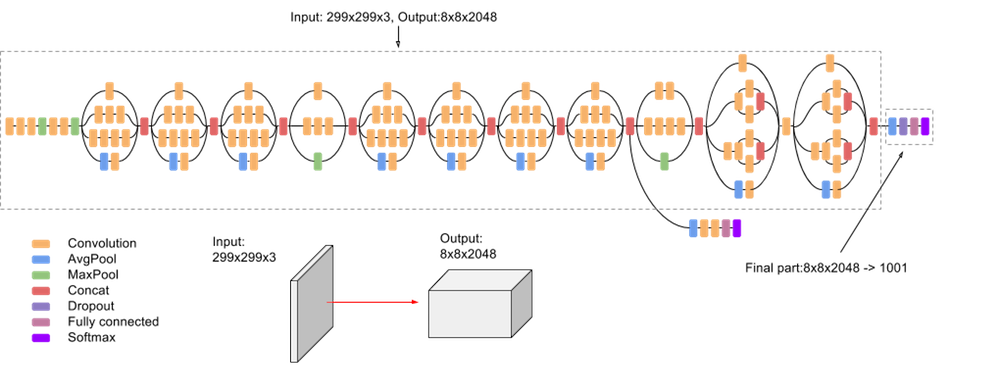

In [39]:
%%time
tf.keras.backend.clear_session()

base_model = tf.keras.applications.InceptionV3(
    weights='./pretrained_models/inception_v3_weights_tf_dim_ordering_tf_kernels_notop.h5', 
    include_top=False, 
    input_shape=input_shape
)
base_model.trainable = False

model_inceptionv3 = tf.keras.Sequential()
model_inceptionv3.add(base_model)
model_inceptionv3.add(tf.keras.layers.Flatten())

model_inceptionv3.add(tf.keras.layers.Dense(4, activation='softmax'))

model_inceptionv3.compile(loss='categorical_crossentropy',
    optimizer=tf.keras.optimizers.Adam(0.001),
    metrics=['acc']
)
model_inceptionv3.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 inception_v3 (Functional)   (None, 5, 5, 2048)        21802784  
                                                                 
 flatten (Flatten)           (None, 51200)             0         
                                                                 
 dense (Dense)               (None, 4)                 204804    
                                                                 
Total params: 22007588 (83.95 MB)
Trainable params: 204804 (800.02 KB)
Non-trainable params: 21802784 (83.17 MB)
_________________________________________________________________
CPU times: total: 2.34 s
Wall time: 8.68 s


### 模型训练

In [40]:
%%time
checkpoint = tf.keras.callbacks.ModelCheckpoint('save_models/inceptionv3_best.h5', monitor='acc', verbose=1, mode='max',save_best_only=True)
early = tf.keras.callbacks.EarlyStopping(monitor="acc", mode="max",restore_best_weights=True, patience=5)
callbacks_list = [checkpoint,early]

history = model_inceptionv3.fit(
        train_ds,
        validation_data=val_ds,
        epochs=25, 
        shuffle=True, 
        verbose=True,
        callbacks=callbacks_list)

Epoch 1/25
88/88 [==============================] - ETA: 0s - loss: 1.8652 - acc: 0.7832
Epoch 1: acc improved from -inf to 0.78324, saving model to save_models\inceptionv3_best.h5


D:\Python3.10.6\lib\site-packages\keras\src\engine\training.py:3103: UserWarning:

You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.



88/88 [==============================] - 361s 4s/step - loss: 1.8652 - acc: 0.7832 - val_loss: 0.6067 - val_acc: 0.8725
Epoch 2/25
88/88 [==============================] - ETA: 0s - loss: 0.4541 - acc: 0.8973
Epoch 2: acc improved from 0.78324 to 0.89731, saving model to save_models\inceptionv3_best.h5
88/88 [==============================] - 335s 4s/step - loss: 0.4541 - acc: 0.8973 - val_loss: 0.4220 - val_acc: 0.8967
Epoch 3/25
88/88 [==============================] - ETA: 0s - loss: 0.3329 - acc: 0.9242
Epoch 3: acc improved from 0.89731 to 0.92419, saving model to save_models\inceptionv3_best.h5
88/88 [==============================] - 344s 4s/step - loss: 0.3329 - acc: 0.9242 - val_loss: 0.4356 - val_acc: 0.9038
Epoch 4/25
88/88 [==============================] - ETA: 0s - loss: 0.2827 - acc: 0.9301
Epoch 4: acc improved from 0.92419 to 0.93006, saving model to save_models\inceptionv3_best.h5
88/88 [==============================] - 343s 4s/step - loss: 0.2827 - acc: 0.9301 - val

#### 绘制模型训练的损失函数

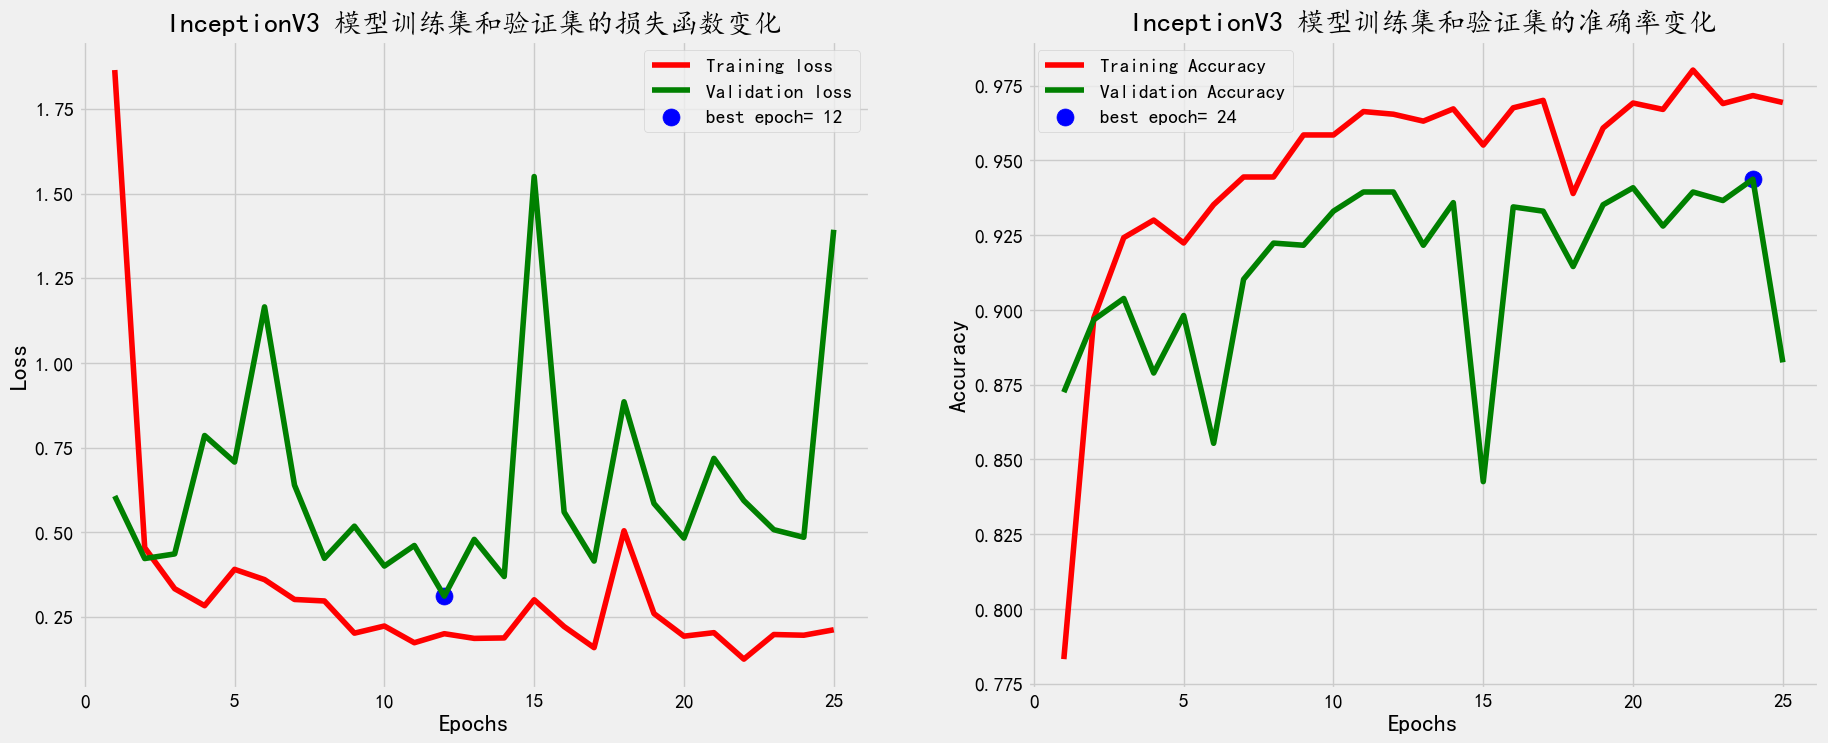

In [41]:
# Define needed variables
tr_acc = history.history['acc']
tr_loss = history.history['loss']
val_acc = history.history['val_acc']
val_loss = history.history['val_loss']
index_loss = np.argmin(val_loss)
val_lowest = val_loss[index_loss]
index_acc = np.argmax(val_acc)
acc_highest = val_acc[index_acc]
Epochs = [i+1 for i in range(len(tr_acc))]
loss_label = f'best epoch= {str(index_loss + 1)}'
acc_label = f'best epoch= {str(index_acc + 1)}'

# Plot training history
plt.figure(figsize= (20, 8))
plt.style.use('fivethirtyeight')

plt.subplot(1, 2, 1)
plt.plot(Epochs, tr_loss, 'r', label= 'Training loss')
plt.plot(Epochs, val_loss, 'g', label= 'Validation loss')
plt.scatter(index_loss + 1, val_lowest, s= 150, c= 'blue', label= loss_label)
plt.title('InceptionV3 模型训练集和验证集的损失函数变化')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(Epochs, tr_acc, 'r', label= 'Training Accuracy')
plt.plot(Epochs, val_acc, 'g', label= 'Validation Accuracy')
plt.scatter(index_acc + 1 , acc_highest, s= 150, c= 'blue', label= acc_label)
plt.title('InceptionV3 模型训练集和验证集的准确率变化')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout
plt.show()

In [42]:
train_result = model_inceptionv3.evaluate(train_ds)
val_result = model_inceptionv3.evaluate(val_ds)

inceptionv3_eval_result = pd.DataFrame(zip(train_result,val_result),columns=['Train','Val'],index=['Loss','Acc'])
inceptionv3_eval_result

22/22 [==============================] - 76s 3s/step - loss: 1.3584 - acc: 0.8889


,Train,Val
Loss,0.638219,1.358395
Acc,0.924898,0.888889


In [43]:
ypred_val = model_inceptionv3.predict(val_ds[0][0])
ypred_val = np.argmax(ypred_val, axis=1)

true_val = np.argmax(val_ds[0][-1], axis=1)

print("混淆矩阵：")
print(confusion_matrix(true_val, ypred_val))
print("详细评估指标：")
print('\n',classification_report(ypred_val, true_val))

2/2 [==============================] - 6s 1s/step
混淆矩阵：
[[13  0  0  0]
 [ 0 14  0  0]
 [ 1  0 17  1]
 [ 1  6  1 10]]
详细评估指标：

               precision    recall  f1-score   support

           0       1.00      0.87      0.93        15
           1       1.00      0.70      0.82        20
           2       0.89      0.94      0.92        18
           3       0.56      0.91      0.69        11

    accuracy                           0.84        64
   macro avg       0.86      0.86      0.84        64
weighted avg       0.89      0.84      0.85        64



## 结论

In [44]:
vgg16_eval_result = vgg16_eval_result['Val'].to_dict()
inceptionv3_eval_result = inceptionv3_eval_result['Val'].to_dict()

In [45]:
vgg16_eval_result

{'Loss': 0.16120412945747375, 'Acc': 0.9394586682319641}

In [46]:
inceptionv3_eval_result

{'Loss': 1.3583953380584717, 'Acc': 0.8888888955116272}

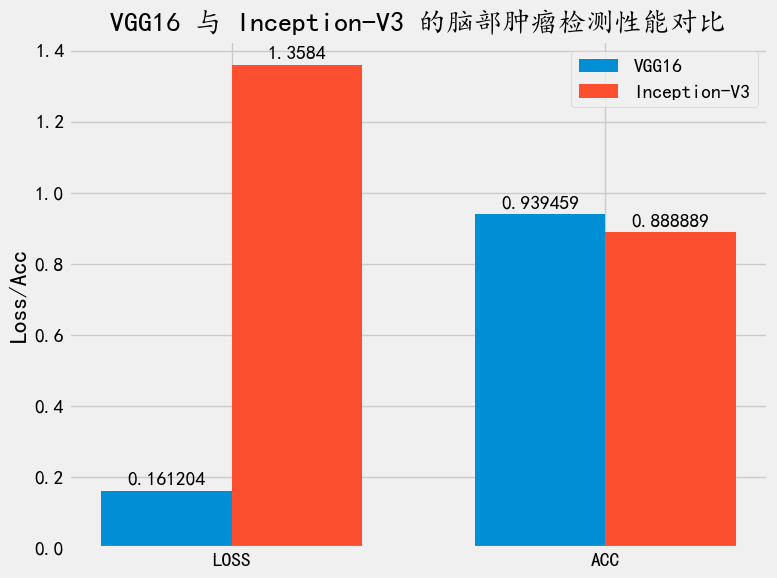

In [47]:
labels = ['LOSS', 'ACC']
vgg16_evals = [vgg16_eval_result['Loss'], vgg16_eval_result['Acc']]
inceptionv3_evals = [inceptionv3_eval_result['Loss'], inceptionv3_eval_result['Acc']]

x = np.arange(len(labels))  # the label locations
width = 0.35  # the width of the bars

fig, ax = plt.subplots(figsize=(8, 6), dpi=100)
rects1 = ax.bar(x - width/2, vgg16_evals, width, label='VGG16')
rects2 = ax.bar(x + width/2, inceptionv3_evals, width, label='Inception-V3')

# Add some text for labels, title and custom x-axis tick labels, etc.
ax.set_ylabel('Loss/Acc')
ax.set_title('VGG16 与 Inception-V3 的脑部肿瘤检测性能对比')
ax.set_xticks(x, labels)
ax.legend()

ax.bar_label(rects1, padding=3)
ax.bar_label(rects2, padding=3)

fig.tight_layout()
 
plt.show()